In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import layers
from tensorflow.keras.preprocessing.sequence import pad_sequences

(x_train, y_train), (x_test, y_test) = keras.datasets.imdb.load_data(num_words=10000)

x_train = pad_sequences(x_train, maxlen=200)
x_test = pad_sequences(x_test, maxlen=200)

model = keras.Sequential([
    layers.Embedding(input_dim=10000, output_dim=16),
    layers.GlobalAveragePooling1D(),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.fit(x_train, y_train, epochs=10, validation_data=(x_test, y_test))

loss, acc = model.evaluate(x_test, y_test)

print("Loss:", loss)
print("Accuracy:", acc)

start = 5
end = 11

predictions = model.predict(x_test[start:end])

word_index = keras.datasets.imdb.get_word_index()
reverse_word_index = {value: key for key, value in word_index.items()}

def decode_review(encoded_review):
    return " ".join([reverse_word_index.get(i - 3, "?") for i in encoded_review])

for i in range(end - start):
    print("\nReview:", decode_review(x_test[start + i]))
    print("Actual:", "Positive" if y_test[start + i] == 1 else "Negative")
    print("Predicted:", "Positive" if predictions[i][0] > 0.5 else "Negative")

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.7520 - loss: 0.5285 - val_accuracy: 0.8294 - val_loss: 0.3736
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8817 - loss: 0.2911 - val_accuracy: 0.8780 - val_loss: 0.2967
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9091 - loss: 0.2317 - val_accuracy: 0.8763 - val_loss: 0.2926
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9197 - loss: 0.2047 - val_accuracy: 0.8574 - val_loss: 0.3395
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9321 - loss: 0.1775 - val_accuracy: 0.8650 - val_loss: 0.3328
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9399 - loss: 0.1611 - val_accuracy: 0.8670 - val_loss: 0.3307
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9471 - loss: 0.1456 - val_accuracy: 0.8613 - val_loss: 0.3553
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9534 - loss: 0.1321 - val_accuracy: 0.

In [ ]:
!kaggle datasets download -d belsonraja/face-mask-dataset-with-and-without-mask

In [ ]:
!unzip face-mask-dataset-with-and-without-mask.zip

Found 3067 images belonging to 2 classes.
Found 766 images belonging to 2 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/3
30/96 ━━━━━━━━━━━━━━━━━━━━ 1:11 1s/step - accuracy: 0.5948 - loss: 0.6914

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


96/96 ━━━━━━━━━━━━━━━━━━━━ 118s 1s/step - accuracy: 0.8536 - loss: 0.3332 - val_accuracy: 0.9386 - val_loss: 0.1892
Epoch 2/3
96/96 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0.9341 - loss: 0.1825 - val_accuracy: 0.9386 - val_loss: 0.1631
Epoch 3/3
96/96 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step - accuracy: 0.9485 - loss: 0.1431 - val_accuracy: 0.9465 - val_loss: 0.1577
24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 356ms/step - accuracy: 0.9465 - loss: 0.1577
Loss: 0.15769678354263306
Accuracy: 0.9464752078056335
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step


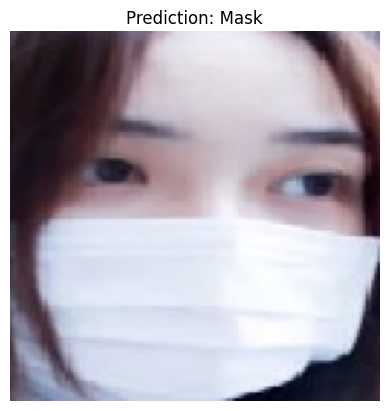

In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image

data_dir = "/content/facemask-dataset/dataset"

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = train_datagen.flow_from_directory(
    data_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='binary',
    subset='training'
)

val_data = train_datagen.flow_from_directory(
    data_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

model = keras.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.fit(train_data, epochs=3, validation_data=val_data)

loss, acc = model.evaluate(val_data)
print("Loss:", loss)
print("Accuracy:", acc)


img_path = "/content/facemask-dataset/dataset/with_mask/with_mask (1).jpg"

img = image.load_img(img_path, target_size=(128,128))
img_array = image.img_to_array(img)/255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

plt.imshow(img)
plt.axis('off')

if prediction[0][0] > 0.5:
    plt.title("Prediction: No Mask")
else:
    plt.title("Prediction: Mask")

plt.show()